# Gene Localization Analysis

In [36]:
# imports
import os
import polars as pl
import pandas as pd
import numpy as np
from tqdm import tqdm
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import umap
from sklearn.decomposition import PCA
from functools import reduce
import operator
from adjustText import adjust_text

import sys
sys.path.append("../../../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../1_snakemake_pipeline/2025_varchamp_snakemake")
from img_utils import *

sns.set_style(style='white')
sns.set_context("notebook", font_scale=.9)

## QC-ed PQ files
ALL_PROF_QC = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier.parquet"
PASS_QC_PROF_PQ = PROF_DIR + "/{batch_id}/profiles_tcdropped_filtered_var_mad_outlier_featselect_filtcells.parquet"

## 1. Loading data

In [14]:
imaging_summary_clinvar = pl.read_csv("../../3_outputs/imaging_analyses_summary_clinvar.tsv", separator="\t", infer_schema_length=10000000)

In [127]:
gene_loc_df = pl.read_csv("../../1_inputs/subcell_loc/hpa_subcellular_location_annotations/subcellular_location_data.tsv", separator="\t", infer_schema_length=10000000)
gene_loc_df

Gene,Gene name,Reliability,Main location,Additional location,Extracellular location,Enhanced,Supported,Approved,Uncertain,Single-cell variation intensity,Single-cell variation spatial,Cell cycle dependency,GO id
str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""ENSG00000000003""","""TSPAN6""","""Approved""","""Cell Junctions;Cytosol""","""Nucleoli fibrillar center""",null,null,null,"""Cell Junctions;Cytosol;Nucleol…",null,"""Cytosol""",null,null,"""Cell Junctions (GO:0030054);Cy…"
"""ENSG00000000457""","""SCYL3""","""Supported""","""Cytosol;Golgi apparatus""",null,null,null,"""Cytosol;Golgi apparatus""",null,null,null,null,null,"""Cytosol (GO:0005829);Golgi app…"
"""ENSG00000000460""","""C1orf112""","""Supported""","""Nucleoplasm""","""Nucleoli""",null,null,"""Nucleoli;Nucleoplasm""",null,null,null,null,null,"""Nucleoli (GO:0005730);Nucleopl…"
"""ENSG00000000938""","""FGR""","""Approved""","""Plasma membrane""","""Aggresome""",null,null,null,"""Aggresome;Plasma membrane""",null,null,null,null,"""Aggresome (GO:0016235);Plasma …"
"""ENSG00000000971""","""CFH""","""Approved""","""Vesicles""",null,"""Predicted to be secreted""",null,null,"""Vesicles""",null,null,null,null,"""Vesicles (GO:0043231)"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENSG00000290292""","""HOMEZ""","""Supported""","""Nucleoli""","""Cytosol;Nucleoplasm""",null,null,"""Nucleoli;Nucleoplasm""","""Cytosol""",null,null,null,null,"""Cytosol (GO:0005829);Nucleoli …"
"""ENSG00000290315""","""ENSG00000290315""","""Approved""","""Cytosol""","""Rods & Rings""",null,null,null,"""Cytosol;Rods & Rings""",null,"""Cytosol;Rods & Rings""",null,null,"""Cytosol (GO:0005829);Rods & Ri…"
"""ENSG00000290317""","""ENSG00000290317""","""Approved""","""Nucleoplasm""","""Golgi apparatus""",null,null,null,"""Golgi apparatus;Nucleoplasm""",null,null,null,null,"""Golgi apparatus (GO:0005794);N…"


In [139]:
gene_loc_df = pl.read_csv("../../1_inputs/subcell_loc/hpa_subcellular_location_annotations/subcellular_location_data.tsv", separator="\t", infer_schema_length=10000000)
gene_loc_opencell_df = pl.read_csv("../../1_inputs/subcell_loc/opencell_subcellular_location_annot/opencell-localization-annotations.csv", infer_schema_length=10000000)
gene_loc_all_df = gene_loc_df.select(
    pl.col(["Gene", "Gene name", "Main location", "Approved", "GO id"])
).join(
    gene_loc_opencell_df,
    left_on=["Gene name", "Gene"],
    right_on=["target_name", "ensg_id"],
    how="full",
    coalesce=True
).with_columns(
    pl.when(pl.col("Approved").is_not_null())
    .then(pl.col("Approved"))
    .when((pl.col("Approved").is_null())&(pl.col("annotations_grade_3").is_not_null()))
    .then(pl.col("annotations_grade_3"))
    .otherwise(pl.lit("Uncertain"))
    .alias("Final_Loc")
)

In [140]:
allele_meta_df = pl.DataFrame()
allele_meta_df_dict, img_well_qc_sum_dict = {}, {}

for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
    for batch_id in bio_rep_batches:
        allele_meta_df_batch = pl.DataFrame()
        platemaps = [file for file in os.listdir(PLATEMAP_DIR.format(batch_id=batch_id)) if file.endswith(".txt")]
        for platemap in platemaps:
            platemap_df = pl.read_csv(os.path.join(PLATEMAP_DIR.format(batch_id=batch_id), platemap), separator="\t", infer_schema_length=100000)
            allele_meta_df_batch = pl.concat([allele_meta_df_batch, 
                                        platemap_df.filter((pl.col("node_type").is_not_null()))], # (~pl.col("node_type").is_in(["TC","NC","PC"]))&
                                        how="diagonal_relaxed").sort("plate_map_name")
            allele_meta_df_batch = allele_meta_df_batch.with_columns(pl.col("plate_map_name").alias("plate_map")) ## str.split('_').list.get(0).
            # display(allele_meta_df.head())
        allele_meta_df = pl.concat([
            allele_meta_df,
            allele_meta_df_batch
        ], how="diagonal_relaxed")#.sort("plate_map_name") ## (~pl.col("node_type").is_in(["TC","NC","PC"]))&
    allele_meta_df_dict[bio_rep] = allele_meta_df_batch

    img_well_qc_sum = pl.read_csv(f"{IMGS_QC_METRICS_DIR}/{bio_rep}/plate-well-level_img_qc_sum.csv")
    img_well_qc_sum = img_well_qc_sum.with_columns(
        pl.col("channel").replace("DAPI", "DNA").alias("channel")
    )
    img_well_qc_sum_morph = img_well_qc_sum.filter(pl.col("channel")!="GFP")
    img_well_qc_sum_morph = img_well_qc_sum_morph.group_by(["plate","well"]).agg(
        pl.col("is_bg").max().alias("is_bg"),
        pl.col("s2n_ratio").mean().alias("s2n_ratio")
    ).with_columns(pl.lit("Morph").alias("channel"))
    img_well_qc_sum = pl.concat([
        img_well_qc_sum.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
        img_well_qc_sum_morph.select(pl.col(["plate","well","channel","is_bg","s2n_ratio"])),
    ], how="vertical_relaxed")
    img_well_qc_sum_dict[bio_rep] = img_well_qc_sum

## 2. Loading CellProfiler Features per Each Gene

In [141]:
feat = "GFP"
gene_list = imaging_summary_clinvar.unique("Gene")["Gene"].to_list()
bio_reps = list(imaging_summary_clinvar["Metadata_Bio_Batch"].unique())

### 2.1 CP features per each gene

In [46]:
# # Paths
# ref_var_cell_qc_prof_df = pl.DataFrame()
# target_gene_alleles = []
# meta_cols = [
#     "Metadata_CellID",
#     "Metadata_gene_allele",
#     "Metadata_Well",
#     "Metadata_Plate",
#     "Metadata_node_type"
# ]

# # Get meta features
# for bio_rep in bio_reps:
#     bio_rep_batches = BIO_REP_BATCHES_DICT[bio_rep]
#     for batch_id in bio_rep_batches:
#         batch_alleles = (
#             pl.scan_parquet(
#                 PASS_QC_PROF_PQ.format(batch_id=batch_id)
#             )
#             .filter(pl.col("Metadata_gene_allele").is_in(gene_list))
#             .with_columns(
#                 pl.concat_str(
#                     [
#                         "Metadata_Plate",
#                         "Metadata_Well",
#                         "Metadata_ImageNumber",
#                         "Metadata_ObjectNumber",
#                     ],
#                     separator="_",
#                 ).alias("Metadata_CellID")
#             )
#         ).collect()
#         # feat_cols = [col for col in batch_alleles.columns if feat.lower() in col.lower()]
#         batch_alleles = batch_alleles.join(
#             img_well_qc_sum_dict[bio_rep].filter(pl.col("channel")==feat).select(pl.col("plate", "well", "is_bg")),
#             left_on=["Metadata_Plate", "Metadata_Well"],
#             right_on=["plate", "well"]
#         ).filter(
#             ~pl.col("is_bg")
#         ).select(pl.col(meta_cols))
#         ref_var_cell_qc_prof_df = pl.concat([ref_var_cell_qc_prof_df, batch_alleles], how="diagonal_relaxed")

In [47]:
# # Paths
# ref_var_cell_all_prof_list = []
# for bio_rep, bio_rep_batches in BIO_REP_BATCHES_DICT.items():
#     for batch_id in bio_rep_batches:
#         batch_alleles = (
#             pl.scan_parquet(
#                 ALL_PROF_QC.format(batch_id=batch_id)
#             )
#             .filter(pl.col("Metadata_gene_allele").is_in(gene_list))
#             .with_columns(
#                 pl.concat_str(
#                     [
#                         "Metadata_Plate",
#                         "Metadata_Well",
#                         "Metadata_ImageNumber",
#                         "Metadata_ObjectNumber",
#                     ],
#                     separator="_",
#                 ).alias("Metadata_CellID")
#             )
#         )
#         ref_var_cell_all_prof_list.append(batch_alleles)

# if feat == "Morph":
#     all_feat_cols = reduce(set.intersection, map(set, [[col for col in ref_var_cell_all_prof.collect_schema() if ("AGP".lower() in col.lower() or "DNA".lower() in col.lower() or "Mito".lower() in col.lower()) \
#                                                     and ("Brightfield".lower() not in col.lower() and "GFP".lower() not in col.lower())] for ref_var_cell_all_prof in ref_var_cell_all_prof_list]))
# else:
#     all_feat_cols = reduce(set.intersection, map(set, [[col for col in ref_var_cell_all_prof.collect_schema() if (feat.lower() in col.lower()) and ("Brightfield".lower() not in col.lower())] for ref_var_cell_all_prof in ref_var_cell_all_prof_list]))

# select_cols = list(all_feat_cols) + ["Metadata_CellID"]
# ref_var_cell_all_prof_df = pl.concat([batch_alleles.select(select_cols).collect() for batch_alleles in ref_var_cell_all_prof_list])
# # This method of joining ensures that only cells past filters are included in the abundance analysis
# ref_var_cell_all_prof_df = ref_var_cell_qc_prof_df.join(ref_var_cell_all_prof_df, 
#                                                         on="Metadata_CellID", how="left", coalesce=True)

In [48]:
# ref_var_cell_all_prof_df = ref_var_cell_all_prof_df.with_columns(
#     pl.col("Metadata_Plate")
#       # capture a “B” followed by any non-underscore chars up to the first “A”
#       .str.extract(r"(B[^_]*?A)", 1)
#       .alias("Metadata_Batch")
# ).with_columns(
#     pl.col("Metadata_Batch").replace(BIO_BATCH_MAP_DICT).alias("Metadata_Bio_Batch")
# )

# ref_var_allele_batch_all_prof_df = ref_var_cell_all_prof_df.group_by(
#     "Metadata_Plate", "Metadata_Well", "Metadata_gene_allele", "Metadata_Bio_Batch"
# ).agg(
#     pl.col(col).median().alias(col)
#     for col in all_feat_cols
#     if not col.startswith("Metadata_")
# ).group_by(
#     "Metadata_gene_allele", "Metadata_Bio_Batch" #
# ).agg(
#     pl.col(col).median().alias(col)
#     for col in all_feat_cols
#     if not col.startswith("Metadata_")
# ).unique(subset=["Metadata_gene_allele","Metadata_Bio_Batch"]) ## 

# non_null_cols_batch = [col for col in ref_var_allele_batch_all_prof_df.columns if not ref_var_allele_batch_all_prof_df[col].is_null().any() and "Metadata" not in col]
# var_allele_meta_cols = [col for col in ref_var_allele_batch_all_prof_df.columns if "Metadata" in col]
# ref_var_allele_batch_all_prof_df = ref_var_allele_batch_all_prof_df.select(
#     var_allele_meta_cols+non_null_cols_batch
# )

In [49]:
# ref_var_allele_batch_all_prof_df.write_csv("../../3_outputs/agg_gene_batch_cp_profiles.csv")

### 2.2 Loading Gene CP profiles

In [142]:
ref_var_allele_batch_all_prof_df = pl.read_csv("../../3_outputs/agg_gene_batch_cp_profiles.csv")

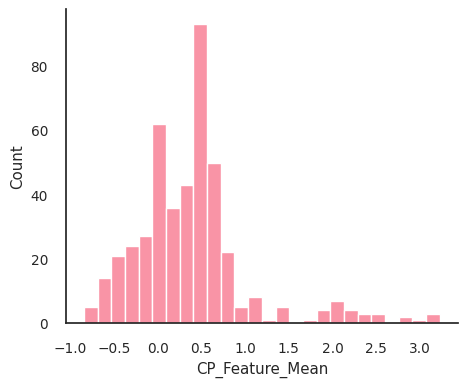

In [143]:
sns.displot(
    x=ref_var_allele_batch_all_prof_df.select(
        pl.col([c for c in ref_var_allele_batch_all_prof_df.columns if "Meta" not in c])
    ).mean().transpose(include_header=True).rename({"column_0": "CP_Feature_Mean"})["CP_Feature_Mean"],
    height=4, aspect=1.2
)

In [144]:
from utils import *
## normalize the features
ref_var_allele_batch_proc_prof_df = inverse_normal_transform(ref_var_allele_batch_all_prof_df)
## remove corr features
ref_var_allele_batch_proc_prof_df = remove_corr_feats(ref_var_allele_batch_proc_prof_df, corr_thres=0.9)

Computing UMAP embedding...


<Axes: xlabel='UMAP1', ylabel='UMAP2'>

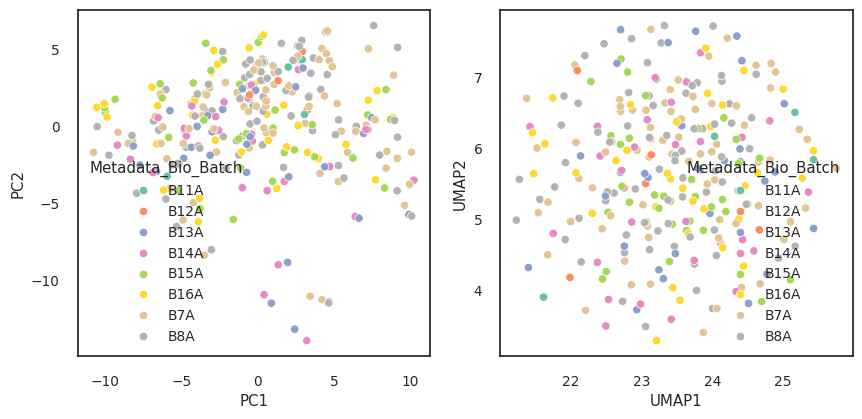

In [53]:
# UMAP - excellent for binary/sparse data
print("Computing UMAP embedding...")
umap_reducer = umap.UMAP(n_components=2, random_state=42, 
                       metric='jaccard', n_neighbors=15, min_dist=0.1)
X_umap = umap_reducer.fit_transform(ref_var_allele_batch_proc_prof_df.select(
    [c for c in ref_var_allele_batch_proc_prof_df.columns if "Metadata_" not in c]
).to_numpy())

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(ref_var_allele_batch_proc_prof_df.select(
    [c for c in ref_var_allele_batch_proc_prof_df.columns if "Metadata_" not in c]
).to_numpy())

umap_df = pd.DataFrame(X_umap, columns=["UMAP1", "UMAP2"])
umap_df["Metadata_Bio_Batch"] = ref_var_allele_batch_proc_prof_df["Metadata_Bio_Batch"]
umap_df["Metadata_gene_allele"] = ref_var_allele_batch_proc_prof_df["Metadata_gene_allele"]

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Metadata_Bio_Batch"] = ref_var_allele_batch_proc_prof_df["Metadata_Bio_Batch"]
pca_df["Metadata_gene_allele"] = ref_var_allele_batch_proc_prof_df["Metadata_gene_allele"]

fig, axes = plt.subplots(1,2, figsize=(10, 4.5))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Metadata_Bio_Batch", palette="Set2", ax=axes[0],
                hue_order=sorted(ref_var_allele_batch_proc_prof_df["Metadata_Bio_Batch"].unique()))
sns.scatterplot(data=umap_df, x="UMAP1", y="UMAP2", hue="Metadata_Bio_Batch", palette="Set2",  ax=axes[1],
               hue_order=sorted(ref_var_allele_batch_proc_prof_df["Metadata_Bio_Batch"].unique()))

__No significant batch effects detected, aggregate the CP profiles to allele level across batches.__

### 2.4 Agg to allele

In [155]:
# ref_batch_all_prof_df = ref_var_allele_batch_all_prof_df.group_by(
#     "Metadata_gene_allele"
# ).agg(
#     pl.col(col).median().alias(col)
#     for col in all_feat_cols
#     if not col.startswith("Metadata_")
# ).unique(subset=["Metadata_gene_allele"])

# ## normalize the features
# ref_batch_proc_prof_df = inverse_normal_transform(ref_batch_all_prof_df)
# ## remove corr features
# ref_batch_proc_prof_df = remove_corr_feats(ref_batch_proc_prof_df, corr_thres=0.9)

# ref_batch_proc_prof_loc_df.group_by("Main location").agg(pl.len())

# gene_loc_df_varchamp = gene_loc_all_df.filter(pl.col("Gene name").is_in(gene_list))
# ref_batch_proc_prof_loc_df = ref_batch_proc_prof_df.join(
#     gene_loc_df_varchamp.select(pl.col(["Gene name", "Final_Loc", "Main location", "Approved", "annotations_grade_3"])),
#     left_on="Metadata_gene_allele",
#     right_on="Gene name",
#     how="left"
# ).with_columns(
#     pl.col("Main location").fill_null("Unknown"),
#     pl.col("Approved").fill_null("Unknown"),
#     pl.col("Final_Loc").fill_null("Unknown"),
# )
# ref_batch_proc_prof_loc_df.write_csv("../../3_outputs/agg_gene_normalized_cp_profiles_subloc.csv")

In [156]:
gene_loc_df_varchamp["Final_Loc"].unique().sort()

Final_Loc
str
"""Acrosome;End piece;Mid piece;P…"
"""Actin filaments"""
"""Actin filaments;Cytosol"""
"""Annulus;End piece;Mid piece;Pr…"
"""Basal body"""
…
"""membrane"""
"""nuclear_membrane"""
"""nucleolus_fc_dfc"""


In [157]:
ref_batch_proc_prof_loc_df = pl.read_csv("../../3_outputs/agg_gene_normalized_cp_profiles_subloc.csv")

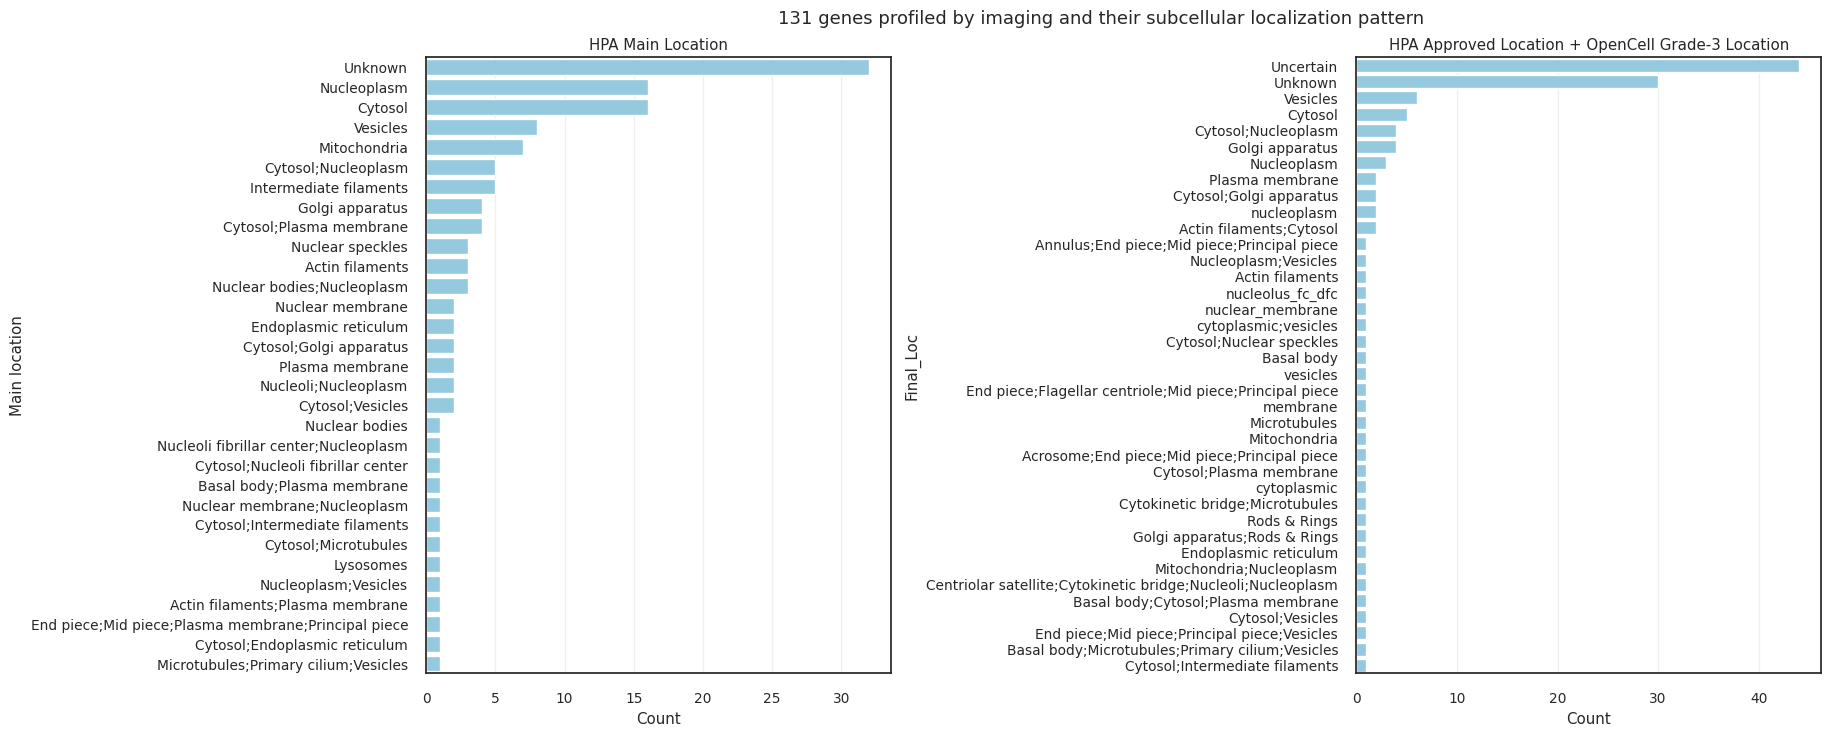

In [162]:
fig, axes = plt.subplots(1,2,figsize=(18, 8))
sns.barplot(
    data=ref_batch_proc_prof_loc_df.group_by("Main location").agg(pl.len()).rename({"len": "Count"}),
    x="Count",
    y="Main location",
    ax=axes[0],
    order=ref_batch_proc_prof_loc_df.group_by("Main location").agg(pl.len()).rename({"len": "Count"}).sort("Count", descending=True)["Main location"],
    color="skyblue"
)
sns.barplot(
    data=ref_batch_proc_prof_loc_df.group_by("Final_Loc").agg(pl.len()).rename({"len": "Count"}),
    x="Count",
    y="Final_Loc",
    ax=axes[1],
    order=ref_batch_proc_prof_loc_df.group_by("Final_Loc").agg(pl.len()).rename({"len": "Count"}).sort("Count", descending=True)["Final_Loc"],
    color="skyblue"
)
axes[0].grid(axis="x", alpha=.3)
axes[0].set_title("HPA Main Location")

axes[1].grid(axis="x", alpha=.3)
axes[1].set_title("HPA Approved Location + OpenCell Grade-3 Location")

plt.suptitle(f"{ref_batch_proc_prof_loc_df.shape[0]} genes profiled by imaging and their subcellular localization pattern", y=.94)
plt.subplots_adjust(wspace=1.)
custom_palette = sns.color_palette("colorblind", 10) + \
                 sns.color_palette("Set2", 8) + \
                 sns.color_palette("Dark2", 8) + \
                 sns.color_palette("Pastel1", 9)

Computing UMAP embedding...


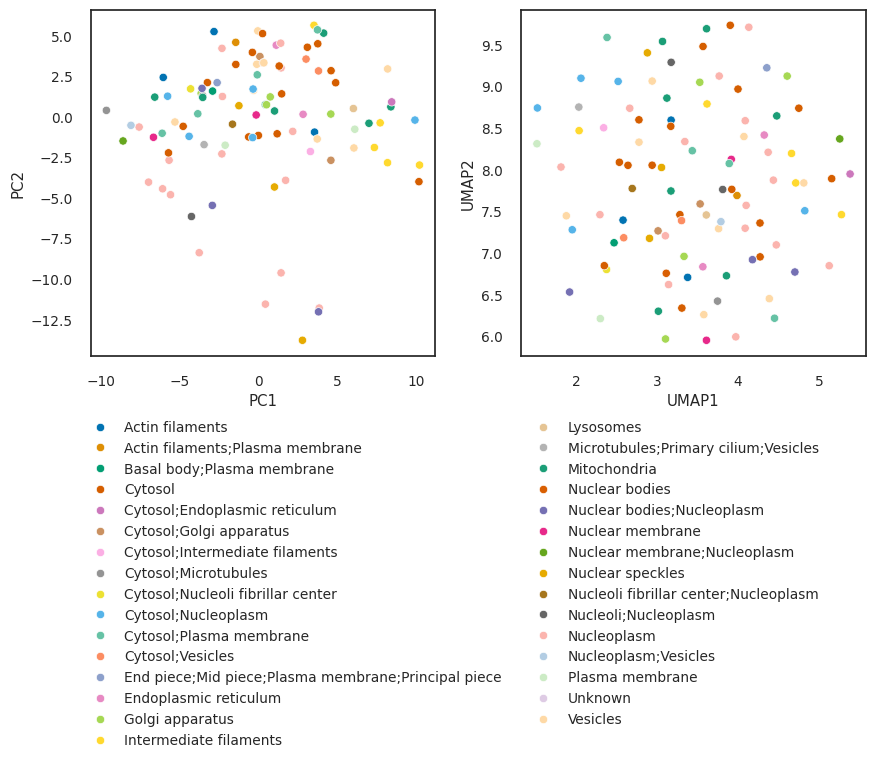

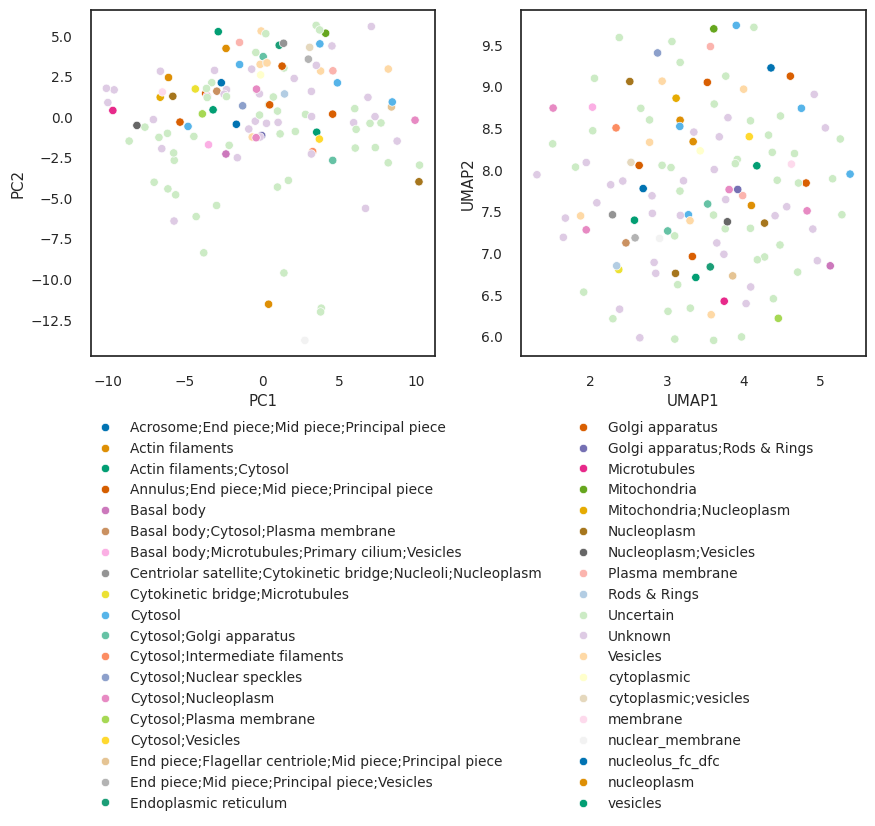

In [159]:
# UMAP - excellent for binary/sparse data
print("Computing UMAP embedding...")
umap_reducer = umap.UMAP(n_components=2, random_state=42, 
                       metric='jaccard', n_neighbors=15, min_dist=0.1)
X_umap = umap_reducer.fit_transform(ref_batch_proc_prof_loc_df.select(
    [c for c in ref_batch_proc_prof_df.columns if "Metadata_" not in c]
).to_numpy())

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(ref_batch_proc_prof_loc_df.select(
    [c for c in ref_batch_proc_prof_df.columns if "Metadata_" not in c]
).to_numpy())

umap_df = pd.DataFrame(X_umap, columns=["UMAP1", "UMAP2"])
umap_df["Main location"] = ref_batch_proc_prof_loc_df["Main location"]
umap_df["Metadata_gene_allele"] = ref_batch_proc_prof_loc_df["Metadata_gene_allele"]
umap_df["Final_Loc"] = ref_batch_proc_prof_loc_df["Final_Loc"]

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["Main location"] = ref_batch_proc_prof_loc_df["Main location"]
pca_df["Metadata_gene_allele"] = ref_batch_proc_prof_loc_df["Metadata_gene_allele"]
pca_df["Final_Loc"] = ref_batch_proc_prof_loc_df["Final_Loc"]

fig, axes = plt.subplots(1,2, figsize=(10, 4.5))
sns.scatterplot(data=pca_df[pca_df["Main location"]!="Unknown"], x="PC1", y="PC2", hue="Main location", palette=custom_palette, ax=axes[0],
                hue_order=sorted(ref_batch_proc_prof_loc_df["Main location"].drop_nulls().unique()), legend=False)
sns.scatterplot(data=umap_df[umap_df["Main location"]!="Unknown"], x="UMAP1", y="UMAP2", hue="Main location", palette=custom_palette,  ax=axes[1],
               hue_order=sorted(ref_batch_proc_prof_loc_df["Main location"].drop_nulls().unique()), legend=True)
axes[1].legend(bbox_to_anchor=(-0.2, -0.15), ncol=2, loc="upper center")
plt.subplots_adjust(wspace=.25)

fig, axes = plt.subplots(1,2, figsize=(10, 4.5))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Final_Loc", palette=custom_palette, ax=axes[0],
                hue_order=sorted(ref_batch_proc_prof_loc_df["Final_Loc"].drop_nulls().unique()), legend=False)
sns.scatterplot(data=umap_df, x="UMAP1", y="UMAP2", hue="Final_Loc", palette=custom_palette,  ax=axes[1],
               hue_order=sorted(ref_batch_proc_prof_loc_df["Final_Loc"].drop_nulls().unique()), legend=True)
axes[1].legend(bbox_to_anchor=(-0.2, -0.15), ncol=2, loc="upper center")
plt.subplots_adjust(wspace=.25)